### Exercise 10.1

We have not explicitly considered or given pseudocode for any Monte Carlo methods in this chapter. What would they be like? Why is it reasonable not to give pseudocode for them? How would they perform on the Mountain Car task?

**Answer**

Monte Carlo methods learn only from complete episodes. In control problems, we start with arbitrally defined policy, which is probably bad and there is a high chance that it will never reach a terminal state, so the episode will never end. This would almost certainly be the case for the Mountain Car task. Figure 10.1 shows that the semi-gradient Sarsa couldn't finish the first episode in 428 steps, where its policy improved after each step. For MC methods, the policy won't change from the beginning, so the first episode would be much longer and probably would never end.

### Exercise 10.2

Give pseudocode for semi-gradient one-step Expected Sarsa for control.

**Answer**

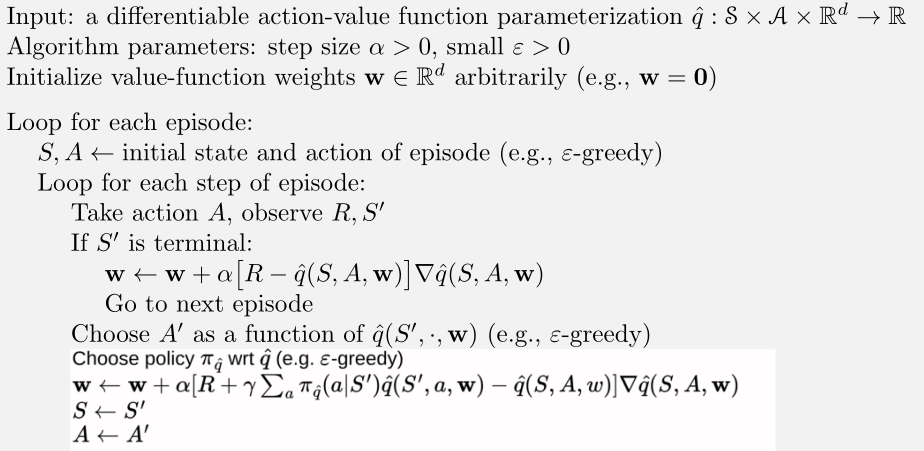

### Exercise 10.3

Why do the results shown in Figure 10.4 have higher standard errors at large $n$ than at small $n$?

**Answer**

Standard errors are higher for large $n$, because the return in each steps depends more on actions chosen by the policy, which is, to some degree, random. This reults in more variance in returns and therefore to higher standard errors.

### Exercise 10.4

Give pseudocode for a differential version of semi-gradient Q-learning.

**Answer**

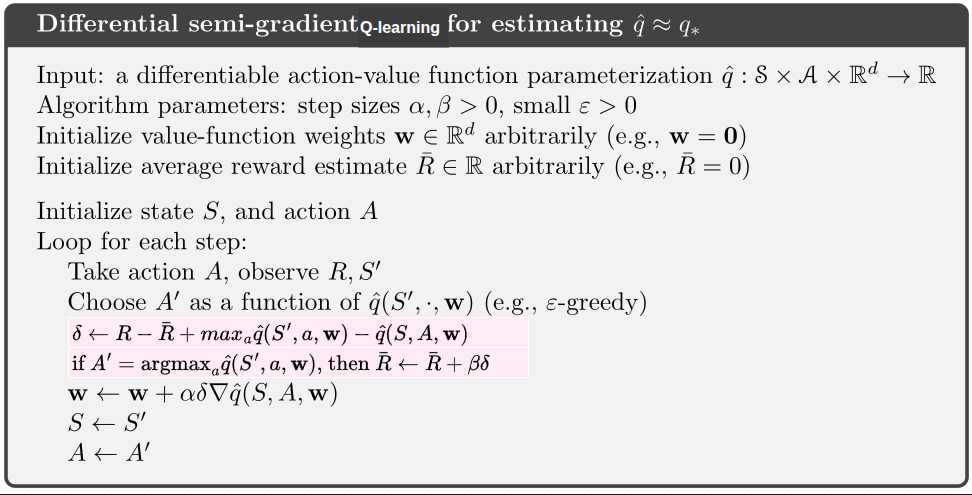

### Exercise 10.5

What equations are needed (beyond 10.10) to specify the differential version of TD(0)?

**Answer**

We also need the update rules for $\mathbf{w}$ and $\bar{R}$

* $\mathbf{w}_{t+1} = \mathbf{w}_t + \alpha \nabla \hat{v}(S_t, \mathbf{w}_t)$
* $\bar{R}_{t+1} = \bar{R}_{t} + \beta \delta $

### Exercise 10.6

Suppose there is an MDP that under any policy produces the deterministic sequence of rewards +1, 0, +1, 0, +1, 0, . . . going on forever. Technically, this violates ergodicity; there is no stationary limiting distribution $\mu_{\pi}$ and the limit (10.7) does not exist. Nevertheless, the average reward (10.6) is well defined. What is it? Now consider two states in this MDP. From A, the reward sequence is exactly as described above, starting with a +1, whereas, from B, the reward sequence starts with a 0 and then continues with +1, 0, +1, 0, . . .. We would like to compute the differential values of A and B. Unfortunately, the differential return (10.9) is not well defined when starting from these states as the implicit limit does not exist. To repair this, one could alternatively define the differential value of a state as
$$
v_{\pi}(s) = \lim_{\gamma \rightarrow 1} \lim_{h \rightarrow \infty} \sum_{t=0}^h \gamma^t \left(\mathbb{E}[R_{t+1} | S_0 = s] - r(\pi) \right)
$$

Under this definition, what are the differential values of states A and B?

**Answer**

Average reward $r(\pi) = \frac{1}{2}$

Differential values:

For state A we have $\mathbb{E}[R_1|S_0 = A] = 1$, $\mathbb{E}[R_2|S_0 = A] = 0$, $E_[R_3|S_0 = A] = 1$ etc.
Therefore
* for $t = 0$: $\mathbb{E}[R_1|S_0 = A] - r(\pi) = 1 - \frac{1}{2} = + \frac{1}{2}$
* for $t = 1$: $\mathbb{E}[R_2|S_0 = A] - r(\pi) = 0 - \frac{1}{2} = - \frac{1}{2}$
* for $t = 2$: $\mathbb{E}[R_3|S_0 = A] - r(\pi) = 1 - \frac{1}{2} = + \frac{1}{2}$ ...

In general for $t \leq 0$:
$$
\mathbb{E}[R_{t+1}|S_0 = A] - r(\pi) = \frac{1}{2} (-1)^t
$$

We substitute into the formula for $v_{\pi}(A)$

$$
v_{\pi}(A) = \lim_{\gamma \rightarrow 1} \lim_{h \rightarrow \infty} \sum_{t=0}^h \gamma^t \frac{1}{2} (-1)^t = \lim_{\gamma \rightarrow 1} \  \frac{1}{2} \sum_{t=0}^{\infty} (-\gamma)^t
$$

Because $\gamma \in (0, 1)$, we can use formula for the sum of a geometric series $S = \frac{a_1}{1-q}$

$$
v_{\pi}(A) = \lim_{\gamma \rightarrow 1} \frac{1}{2} \frac{1}{1-(-\gamma)} = \lim_{\gamma \rightarrow 1} \frac{1}{2} \frac{1}{1 + \gamma} = \frac{1}{4}
$$

For state B, we have $\mathbb{E}[R_1|S_0 = B] = 0$, $\mathbb{E}[R_2|S_0 = B] = 1$, $E_[R_3|S_0 = B] = 0$ etc.
Therefore
* for $t = 0$: $\mathbb{E}[R_1|S_0 = B] - r(\pi) = 0 - \frac{1}{2} = - \frac{1}{2}$
* for $t = 1$: $\mathbb{E}[R_2|S_0 = B] - r(\pi) = 1 - \frac{1}{2} = + \frac{1}{2}$
* for $t = 2$: $\mathbb{E}[R_3|S_0 = B] - r(\pi) = 0 - \frac{1}{2} = - \frac{1}{2}$ ...

In general for $t \leq 0$:
$$
\mathbb{E}[R_{t+1}|S_0 = B] - r(\pi) = -\frac{1}{2} (-1)^t
$$

We substitute into the formula for $v_{\pi}(B)$

$$
v_{\pi}(B) = \lim_{\gamma \rightarrow 1} \lim_{h \rightarrow \infty} \sum_{t=0}^h \gamma^t -\frac{1}{2} (-1)^t = -\lim_{\gamma \rightarrow 1} \frac{1}{2} \sum_{t=0}^{\infty} (-\gamma)^t = -v_{\pi}(A) = -\frac{1}{4}
$$


### Exercise 10.7

Consider a Markov reward process consisting of a ring of three states A, B, and C, with state transitions going deterministically around the ring. A reward of +1 is received upon arrival in A and otherwise the reward is 0. What are the diffrential values of the three states, using (10.13)?

**Answer** 

$$
v_{\pi}(s) = \lim_{\gamma \rightarrow 1} \lim_{h \rightarrow \infty} \sum_{t=0}^h \gamma^t \left(\mathbb{E}[R_{t+1} | S_0 = s] - r(\pi) \right) = \lim_{\gamma \rightarrow 1} \sum_{t=0}^{\infty} \gamma^t \left(\mathbb{E}[R_{t+1} | S_0 = s] - r(\pi) \right)
$$

Average reward: $r(\pi) = \frac{1}{1}$

if $S_0 = A$, then sequence of rewards is 0, 0, 1, 0, 0, 1,...

$\mathbb{E}[R_{t+1} | S_0 = s] - r(\pi) = -\frac{1}{3}, -\frac{1}{3}, \frac{2}{3}, -\frac{1}{3}...$, for $t = 0, 1, 2, 3...$

Then

$$
v_\pi(A) = \lim_{\gamma \rightarrow 1} ((-\frac{1}{3}) + (-\frac{1}{3})\gamma + \frac{2}{3}\gamma^2 + (-\frac{1}{3})\gamma^3 + ...) = \lim_{\gamma \rightarrow 1} -\frac{1}{3} \sum_{k=0}^{\infty} \gamma^{3k} - \frac{1}{3}\gamma \sum_{k=0}^{\infty} \gamma^{3k} + \frac{2}{3} \gamma^2 \sum_{k=0}^{\infty} \gamma^{3k} =
\lim_{\gamma \rightarrow 1} (-\frac{1}{3}-\frac{1}{3}\gamma +\frac{2}{3}\gamma^2)\sum_{k=0}^{\infty} \gamma^{3k} \\
=\lim_{\gamma \rightarrow 1} \frac{1}{3}(2\gamma^2 - \gamma - 1) \frac{1}{1-\gamma^3} =\
\lim_{\gamma \rightarrow 1} \frac{1}{3} \frac{-(2\gamma+1)(1-\gamma)}{(1-\gamma)(1+\gamma+\gamma^2)} =
\lim_{\gamma \rightarrow 1} \frac{1}{3}\frac{-(2\gamma+1)}{1+\gamma+\gamma^2} = \frac{1}{3} \frac{-3}{3} = -\frac{1}{3}
$$

if $S_0 = B$, then sequence of rewards is 0, 1, 0, 0, 1, 0,...

Therefore
$$
v_\pi(B) = \lim_{\gamma \rightarrow 1} (-\frac{1}{3}+\frac{2}{3}\gamma -\frac{1}{3}\gamma^2)\sum_{k=0}^{\infty} \gamma^{3k} = \lim_{\gamma \rightarrow 1} -\frac{1}{3} (\gamma^2 - 2\gamma + 1) \frac{1}{1 - \gamma^3} = \lim_{\gamma \rightarrow 1} -\frac{1}{3} \frac{(1-\gamma)^2}{(1-\gamma)(1+\gamma+\gamma^2)} \\
= \lim_{\gamma \rightarrow 1} -\frac{1}{3} \frac{1-\gamma}{1+\gamma+\gamma^2} = -\frac{1}{3} \frac{0}{3} = 0
$$

if $S_0 = C$, then sequence of rewards 1, 0, 0, 1, 0, 0, ...

Therefore
$$
v_\pi(C) =  \lim_{\gamma \rightarrow 1} (\frac{2}{3}-\frac{1}{3}\gamma -\frac{1}{3}\gamma^2)\sum_{k=0}^{\infty} \gamma^{3k} \\
=  \lim_{\gamma \rightarrow 1} \frac{1}{3} (1-\gamma)(2 + \gamma) \frac{1}{(1-\gamma)(1 + \gamma + \gamma^2)} \\
= \lim_{\gamma \rightarrow 1} \frac{1}{3} \frac{2 + \gamma}{1 + \gamma + \gamma^2} = \frac{1}{3} \frac{3}{3} = \frac{1}{3}
$$

Final answer
* $v_\pi(A) = -\frac{1}{3}$
* $v_\pi(B) = 0$
* $v_\pi(C) = + \frac{1}{3}$

### Exercise 10.8

The pseudocode in the box on page 251 updates $\bar{R}_t$ using $\delta_t$ as an error
rather than simply $R_{t+1} \bar{R}_t$. Both errors work, but using $\delta_t$ is better. To see why, consider the ring MRP of three states from Exercise 10.7. The estimate of the average reward should tend towards its true value of $\frac{1}{3}$. Suppose it was already there and was
held stuck there. What would the sequence of $R_{t+1} - \bar{R}_t$ errors be? What would the sequence of $\delta_t$ errors be (using Equation 10.10)? Which error sequence would produce a more stable estimate of the average reward if the estimate were allowed to change in response to the errors? Why?

**Answer**

Equation 10.10: $\delta_t = R_{t+1} - \bar{R}_t + \hat{v}(S_{t+1}, \mathbf{w}_t) - \hat{v}(S_{t}, \mathbf{w}_t)$

During learning $\hat{v}(S_{t}, \mathbf{w}_t)$ should converge to the true values from Exercise 10.7, and $\bar{R}_t$ should converge to the true $r(\pi)$. Let's assume they already converge precisely to the true values, then:

For transition $A \rightarrow B$:

$$
R_{t+1} - \bar{R}_t = 0 - \frac{1}{3} = - \frac{1}{3}
$$

$$
\delta_t = 0 - \frac{1}{3} + 0 - (-\frac{1}{3}) = 0
$$

For transition $B \rightarrow C$:

$$
R_{t+1} - \bar{R}_t = 0 - \frac{1}{3} = - \frac{1}{3}
$$

$$
\delta_t = 0 - \frac{1}{3} + \frac{1}{3} - 0 = 0
$$

For transition $C \rightarrow A$:

$$
R_{t+1} - \bar{R}_t = 1 - \frac{1}{3} = \frac{2}{3}
$$

$$
\delta_t = 1 - \frac{1}{3} + (-\frac{1}{3}) - \frac{1}{3} = 0
$$

So using $\delta_t$ is more stable than using $R_{t+1} - \bar{R}_t$

### Exercise 10.9

In the differential semi-gradient $n$-step Sarsa algorithm, the step-size
parameter on the average reward, $\beta$ , needs to be quite small so that $\bar{R}$ becomes a good
long-term estimate of the average reward. Unfortunately, $\bar{R}$ will then be biased by its
initial value for many steps, which may make learning inefficient. Alternatively, one could
use a sample average of the observed rewards for $\bar{R}$. That would initially adapt rapidly
but in the long run would also adapt slowly. As the policy slowly changed, $\bar{R}$ would also
change; the potential for such long-term nonstationarity makes sample-average methods
ill-suited. In fact, the step-size parameter on the average reward is a perfect place to use
the unbiased constant-step-size trick from Exercise 2.7. Describe the specific changes
needed to the boxed algorithm for differential semi-gradient $n$-step Sarsa to use this
trick.


**Answer**

Original semi-gradient $n$-step Sarsa

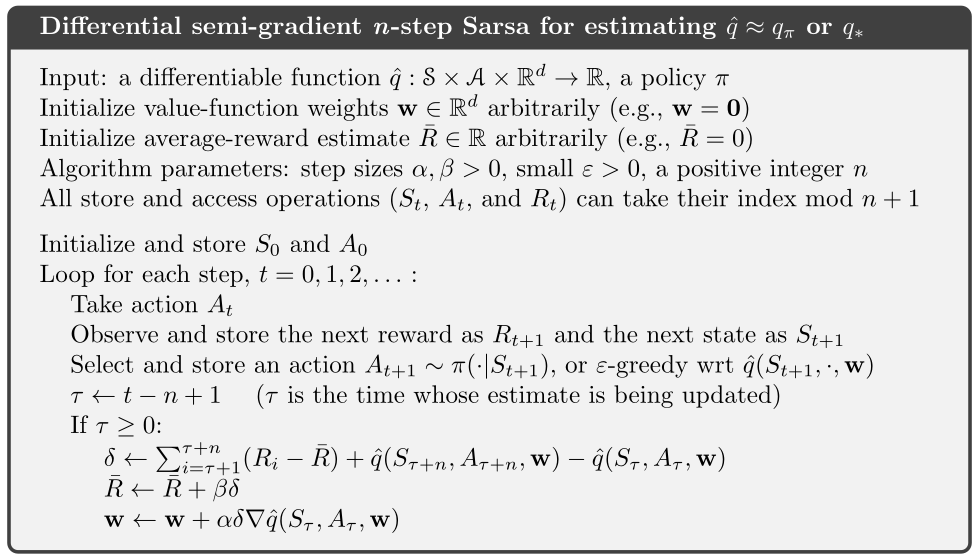

Trick from exercise 2.7 is:
* $\beta_n = \alpha / \bar{o}_n$
* $\bar{o}_n = \bar{o}_n + \alpha (1 - \bar{o}_n)$,   $\bar{o}_0 = 0$

Changes in Sarsa algorithm:
* remove step-size $\beta$ from parameters
* initialize $\bar{o}$ to 0
* Before $\bar{R} \leftarrow \bar{R} + \beta \delta$, add:

    * $\bar{o} \leftarrow \bar{o} + \alpha (1 - \bar{o})$
    * $\beta \leftarrow \alpha / \bar{o}$